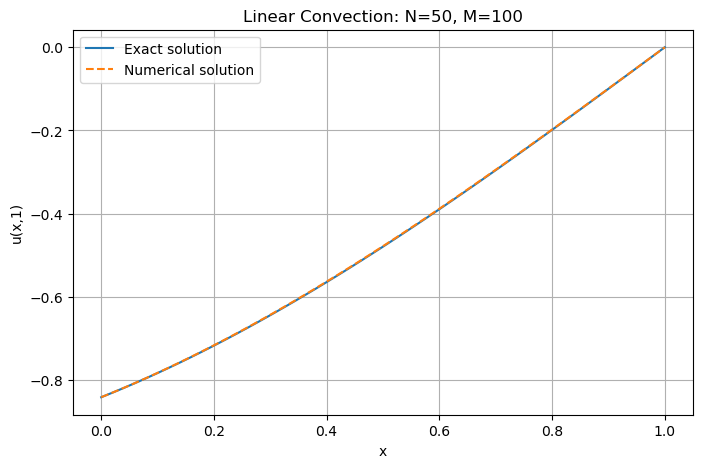

N = 50
M = 100
Maximum absolute error = 0.0011759377234565882



In [3]:
#### programing the linear convection problem

import numpy as np
import matplotlib.pyplot as plt

# initial conditions : u(x,0) = sin(x)
def initial_condition(x):
    return np.sin(x)

# exact solution : u (x,t) = sin(x-ct)
def exact_solution(x, t, c=1):
    return np.sin(x - ( c * t ))

# numerical model : forward time - backwaards space
def linear_convection (N, M, c =1):

    # defining spatial and temporal step size
    dx = 1 / N
    dt = 1 / M

    # dividing [0,1] into N and M intervals
    x = np.linspace(0, 1, N + 1)
    t = np.linspace(0, 1, M + 1)

    # creating a matrix to store u(x,t)
    u = np.zeros((M + 1, N + 1))

    #initial condition : u(x,0) = sin(x)
    u[0, :] = initial_condition(x)

    # boundary condition : u(0,t) = -sin(t)
    u[:, 0] = -np.sin(t)

    # forward iteration
    for j in range(M):
        for i in range(1, N+1):
            u[j+1, i] = u[j, i] - c * dt / dx * (u[j, i] - u[j, i-1])
    return x, u


# comparing numerical and exact solutions :
def compare_solutions(N,M):

    x, u = linear_convection(N, M)

    # numerical solutions at t = 1
    numerical = u[-1, :]

    # exact solutions at t = 1
    exact = exact_solution(x, 1, c=1)

    #computing absolute difference
    error = np.abs(numerical - exact)

    # Plot both solutions           # i asked claude to help me visualise this
    plt.figure(figsize=(8, 5))

    plt.plot(x, exact, label="Exact solution")
    plt.plot(x, numerical, "--", label="Numerical solution")

    plt.xlabel("x")
    plt.ylabel("u(x,1)")
    plt.title(f"Linear Convection: N={N}, M={M}")

    plt.legend()
    plt.grid(True)
    plt.show()

    print("N =", N)
    print("M =", M)
    print("Maximum absolute error =", np.max(error))
    print()


# Choose values for N and M
N = 50
M = 100

# Run the model
compare_solutions(N, M)